# Confusion matrices on the test set (final model)

Final model: single split (no folds), CT + box mask input, class-weighted cross-entropy loss (`train_no_fold.py --mask --loss weighted`), runs in `runs/cls_no_fold_mask_weighted`. Each model's class weights come from its own training targets: model A from the median ratings, model B (retrained) from the readers' shares. Figures are saved in `results/test_no_fold_mask_redoweights`.

One confusion matrix each for models A and B on the 290 test nodules. Each cell is the **mean ± SD over seeds 1-3**
of the number of nodules with that median rating (row) and predicted rating (column); SD is the sample standard
deviation, as in `summary.csv`. The rows add up to the number of test nodules with each median rating.
The colour is the cell's share of its row (the same whether the seeds are summed or averaged).

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT = Path.cwd().parent if Path.cwd().name == "Model" else Path.cwd()
sys.path.insert(0, str(PROJECT / "Model"))       # plots.py
sys.path.insert(0, str(PROJECT / "pipeline"))    # metrics.py
from plots import SURFACE, INK, INK_2, MUTED, GRID, VAL, BLUES, DASHED, _style

RUNS_DIR = PROJECT / "runs" / "cls_no_fold_mask_weighted"
OUT_DIR = PROJECT / "results" / "test_no_fold_mask_redoweights"   # saved next to the other test results of this model
SEEDS = [1, 2, 3]
RATINGS = [1, 2, 3, 4, 5]
P_COLS = [f"p{k}" for k in RATINGS]
KINDS = {"hard": "A", "soft": "B"}

# check these are the final model's runs: CT + mask input, class-weighted loss
for kind in KINDS:
    for s in SEEDS:
        cfg = json.loads((RUNS_DIR / f"{kind}_seed{s}" / "config.json").read_text())
        assert cfg.get("mask") and cfg.get("loss") == "weighted", f"{kind}_seed{s} is not a mask + weighted run"
        if kind == "soft":     # the redone model B: class weights from the readers' shares, not the median ratings
            assert cfg.get("weights_from") == "readers' shares", f"soft_seed{s} still has the old median-rating weights"

labels = pd.read_csv(PROJECT / "data" / "nodules_labels.csv")
test = labels[labels["split"] == "test"].set_index("nodule_key")
hard = test["hard"].to_numpy()
print(f"{len(test)} test nodules")

def probs_of(run):
    """One run's test probabilities, rows in the order of the test nodules."""
    preds = pd.read_csv(RUNS_DIR / run / "test_preds.csv").set_index("nodule_key")
    return preds.loc[test.index, P_COLS].to_numpy()

290 test nodules


## One confusion matrix per seed, then mean and SD per cell

In [2]:
def counts(pred):
    """5 x 5 counts: rows = median rating, columns = predicted rating."""
    c = np.zeros((5, 5), dtype=int)
    for t, p in zip(hard, pred):
        c[t - 1, p - 1] += 1
    return c

per_seed = {kind: np.array([counts(probs_of(f"{kind}_seed{s}").argmax(axis=1) + 1) for s in SEEDS]) for kind in KINDS}
means = {kind: c.mean(axis=0) for kind, c in per_seed.items()}
sds = {kind: c.std(axis=0, ddof=1) for kind, c in per_seed.items()}
for kind, m in KINDS.items():
    print(f"model {m}: rows of the mean matrix add up to {means[kind].sum(axis=1).round(1).tolist()} "
          f"(test nodules per median rating: {[(hard == r).sum() for r in RATINGS]})")

model A: rows of the mean matrix add up to [37.0, 46.0, 136.0, 44.0, 27.0] (test nodules per median rating: [np.int64(37), np.int64(46), np.int64(136), np.int64(44), np.int64(27)])
model B: rows of the mean matrix add up to [37.0, 46.0, 136.0, 44.0, 27.0] (test nodules per median rating: [np.int64(37), np.int64(46), np.int64(136), np.int64(44), np.int64(27)])


## Draw the matrices

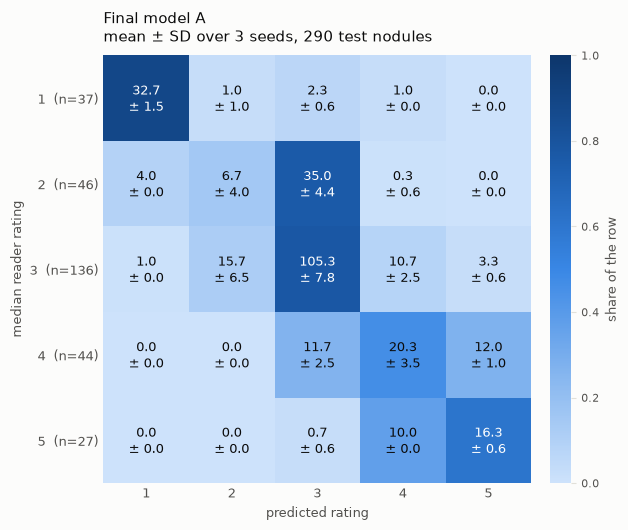

results/test_no_fold_mask_redoweights/confusion_hard_mean.png


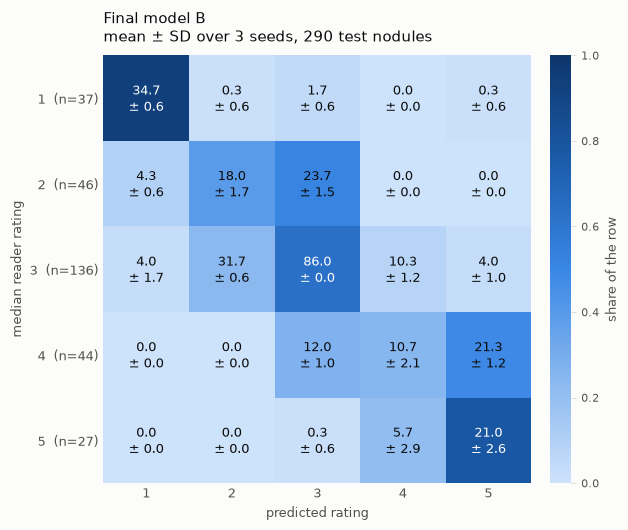

results/test_no_fold_mask_redoweights/confusion_soft_mean.png


In [3]:
def confusion(kind, model, path):
    mean, sd = means[kind], sds[kind]
    share = mean / np.maximum(mean.sum(axis=1, keepdims=True), 1e-9)
    fig, ax = plt.subplots(figsize=(6.2, 5.4), facecolor=SURFACE)
    im = ax.imshow(share, cmap=BLUES, vmin=0, vmax=1)
    for i in range(5):
        for j in range(5):
            ax.text(j, i, f"{mean[i, j]:.1f}\n± {sd[i, j]:.1f}", ha="center", va="center", fontsize=9,
                    linespacing=1.3, color="white" if share[i, j] > 0.55 else INK)
    ax.set_xticks(range(5), RATINGS)
    ax.set_yticks(range(5), [f"{r}  (n={(hard == r).sum()})" for r in RATINGS])
    ax.set_xlabel("predicted rating", fontsize=9, color=INK_2)
    ax.set_ylabel("median reader rating", fontsize=9, color=INK_2)
    ax.tick_params(length=0, labelcolor=INK_2, labelsize=9)
    for spine in ax.spines.values():
        spine.set_visible(False)
    cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cb.set_label("share of the row", fontsize=9, color=INK_2)
    cb.ax.tick_params(labelsize=8, labelcolor=INK_2, color=GRID)
    cb.outline.set_visible(False)
    ax.set_title(f"Final model {model}\nmean ± SD over 3 seeds, 290 test nodules", loc="left", fontsize=11, color=INK, pad=10)
    fig.tight_layout()
    fig.savefig(path, dpi=150, facecolor=SURFACE)
    plt.show()

for kind, m in KINDS.items():
    path = OUT_DIR / f"confusion_{kind}_mean.png"
    confusion(kind, m, path)
    print(path.relative_to(PROJECT))